<a href="https://colab.research.google.com/github/her-syntax/EDAB_Assignments/blob/main/EDAB2724_Assignment3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDAB2724 Assignment 3: Topic Modelling of Bitcoin Tweets
**Group number:** Group 4

**Goal:** Find the main themes (topics) in Bitcoin tweets and show how these themes change over time.

**This is unsupervised learning.** The tweets have no labels. We are not predicting anything. We are discovering and interpreting topics.

### Pipeline used in this notebook
1. Data understanding and audit
2. Text cleaning and pre-processing
3. Exploratory text analysis
4. Text representation (Count and TF-IDF)
5. Topic modelling and model comparison (LDA and NMF, k = 4 to 8)
6. Topic analysis (keywords, examples, topic share, topic by hour, insights)
7. Export `topic_assignments.csv`

## Setup
We only use common libraries (pandas, numpy, matplotlib, seaborn, scikit-learn, wordcloud). No extra downloads are needed, so the notebook is easy to reproduce.

In [ ]:
import os
import re
import html
import json
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation, NMF
from scipy.optimize import linear_sum_assignment
from wordcloud import WordCloud

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

SEED = 42                      # main random seed required by the assignment
os.makedirs("figures", exist_ok=True)
print("Setup complete.")

Setup complete.


## 1. Data understanding and audit
**What we do in this section**
- Load `tweets.csv`
- Check the variable names, data types and the date field
- Find the tweet text column
- Document the final modelling dataset

The file stores many values inside extra quotation marks (for example `"1570926731019825152"`). We remove these quotes first.

In [ ]:
# Upload the file in Google Colab if it is not already in the working folder
DATA_PATH = "tweets.csv"
if not os.path.exists(DATA_PATH):
    from google.colab import files
    files.upload()

raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Rows and columns:", raw.shape)
raw.head(3)

Saving tweets.csv to tweets.csv
Rows and columns: (50000, 19)


,Tweet Id,Tweet URL,Tweet Posted Time,Tweet Content,Tweet Type,Client,Retweets Received,Likes Received,Tweet Location,Tweet Language,User Id,Name,Username,User Bio,Verified or Non-Verified,Profile URL,User Followers,User Following,User Account Creation Date
0,"""1570926731019825152""",https://twitter.com/_MKKX_7/status/15709267310...,17 Sep 2022 00:04:53,"""أدعم التغريدات وفضّلها وأنشرها🙏🏻\n\n🚨سلسلة |#...",ReTweet,"""Twitter for Android""",0,0,"""""",Arabic,"""1138927555946471424""","""ندى الورد 🇸🇦💚""",_MKKX_7,"""إن تحققت أمانينا فالحمد لله و إن تأخرت فهي حت...",Non-Verified,https://twitter.com/_MKKX_7,169.0,4999.0,12-Jun-2019 21:54:24
1,"""1570926731183423488""",https://twitter.com/hungblct/status/1570926731...,17 Sep 2022 00:04:53,"""💧 Unidef Airdrop 💧\n\n🏆 Task: ➕ $9 ...",ReTweet,"""Twitter for Android""",0,0,"""""",English,"""1381649113943482370""","""Nguyễn Hưng""",hungblct,"""Thánh 😇""",Non-Verified,https://twitter.com/hungblct,38.0,3354.0,12-Apr-2021 16:43:22
2,"""1570926713571520513""",https://twitter.com/plusendless/status/1570926...,17 Sep 2022 00:04:49,"""Etheruem has officially merged and moved towa...",ReTweet,"""Twitter for Android""",0,0,"""""",English,"""1381898326728175616""","""Mischa Markus""",plusendless,"""#Bitcoin value = ∞\nsupply limited to 21 mill...",Non-Verified,https://twitter.com/plusendless,128.0,432.0,13-Apr-2021 09:13:54


In [ ]:
# Look at the original variable names and data types
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Tweet Id                    50000 non-null  object 
 1   Tweet URL                   50000 non-null  object 
 2   Tweet Posted Time           50000 non-null  object 
 3   Tweet Content               50000 non-null  object 
 4   Tweet Type                  50000 non-null  object 
 5   Client                      50000 non-null  object 
 6   Retweets Received           50000 non-null  int64  
 7   Likes Received              50000 non-null  int64  
 8   Tweet Location              50000 non-null  object 
 9   Tweet Language              49436 non-null  object 
 10  User  Id                    50000 non-null  object 
 11  Name                        50000 non-null  object 
 12  Username                    50000 non-null  object 
 13  User Bio                    500

In [ ]:
# Remove the extra quotation marks that wrap many text values
for col in raw.columns:
    if pd.api.types.is_string_dtype(raw[col]):
        raw[col] = raw[col].str.strip('"')

print("Missing values per column (original data):")
print(raw.isna().sum()[raw.isna().sum() > 0])

Missing values per column (original data):
Tweet Language                564
Verified or Non-Verified        1
Profile URL                     1
User Followers                  1
User Following                  1
User Account Creation Date      1
dtype: int64


### 1.1 Rename, convert and select the variables we need
We keep seven variables. The other twelve (URLs, user profile details and so on) are not needed for topic modelling, so we leave them out.

In [ ]:
rename_map = {
    "Tweet Id": "tweet_id",
    "Tweet Posted Time": "posted_time",
    "Tweet Content": "tweet_text",
    "Tweet Type": "tweet_type",
    "Tweet Language": "language",
    "Retweets Received": "retweets_received",
    "Likes Received": "likes_received",
}

df = raw.rename(columns=rename_map)[list(rename_map.values())].copy()

# Convert data types
df["tweet_id"] = df["tweet_id"].astype(str)                       # long ids must stay as text
df["posted_time"] = pd.to_datetime(df["posted_time"], format="%d %b %Y %H:%M:%S")

print("Earliest tweet:", df["posted_time"].min())
print("Latest tweet:  ", df["posted_time"].max())
print("Hours covered: ", round((df["posted_time"].max() - df["posted_time"].min()).total_seconds() / 3600, 2))
print("Date conversion failures:", df["posted_time"].isna().sum())
print()
print(df.dtypes)

Earliest tweet: 2022-09-16 17:33:48
Latest tweet:   2022-09-17 00:04:53
Hours covered:  6.52
Date conversion failures: 0

tweet_id                     object
posted_time          datetime64[ns]
tweet_text                   object
tweet_type                   object
language                     object
retweets_received             int64
likes_received                int64
dtype: object


In [ ]:
# Audit table: original name, new name, original type, new type
audit = pd.DataFrame({
    "original_name": list(rename_map.keys()),
    "new_name": list(rename_map.values()),
    "original_type": [str(raw[c].dtype) for c in rename_map.keys()],
    "new_type": [str(df[c].dtype) for c in rename_map.values()],
    "missing_values": [int(df[c].isna().sum()) for c in rename_map.values()],
})
audit

,original_name,new_name,original_type,new_type,missing_values
0,Tweet Id,tweet_id,object,object,0
1,Tweet Posted Time,posted_time,object,datetime64[ns],0
2,Tweet Content,tweet_text,object,object,0
3,Tweet Type,tweet_type,object,object,0
4,Tweet Language,language,object,object,564
5,Retweets Received,retweets_received,int64,int64,0
6,Likes Received,likes_received,int64,int64,0


### 1.2 Quick look at the raw data
This helps us decide what to clean in the next section.

In [ ]:
print("Tweet type counts:")
print(df["tweet_type"].value_counts())
print()
print("Top languages:")
print(df["language"].value_counts(dropna=False).head(8))

Tweet type counts:
tweet_type
ReTweet    33219
Tweet      11765
Reply       5016
Name: count, dtype: int64

Top languages:
language
English     33515
Turkish      8309
Arabic       2592
Spanish      1309
qme          1142
NaN           564
French        500
Japanese      389
Name: count, dtype: int64


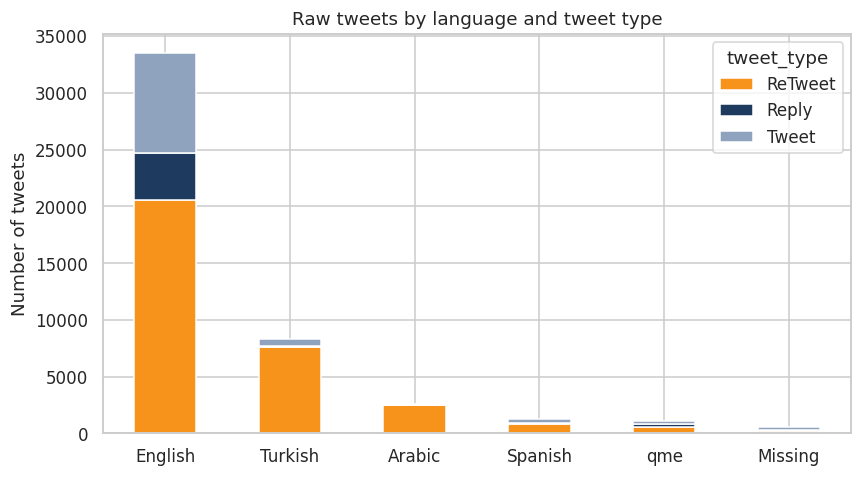

In [ ]:
# Figure: language and tweet type (raw data)
top_langs = df["language"].fillna("Missing").value_counts().head(6).index
lang_type = (
    df.assign(language=df["language"].fillna("Missing"))
      .query("language in @top_langs")
      .groupby(["language", "tweet_type"]).size().unstack(fill_value=0)
      .loc[top_langs]
)
ax = lang_type.plot(kind="bar", stacked=True, figsize=(8, 4.5), color=["#F7931A", "#1F3A5F", "#8FA3BF"])
ax.set_title("Raw tweets by language and tweet type")
ax.set_xlabel("")
ax.set_ylabel("Number of tweets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figures/fig_language_type.png", dpi=150)
plt.show()

## 2. Text cleaning and pre-processing
We follow the same flow we used in class: **raw text, cleaning, tokenisation, stop word removal, lemmatisation**.

We also add tweet-specific steps (language filter, retweets, duplicates, offensive tweets).

We keep a log after each step so we can show how many tweets remain.

In [ ]:
step_log = []
def log_step(name, data):
    step_log.append({"step": name, "tweets_remaining": len(data)})

log_step("Raw data", df)

# Step 1: missing or blank tweet text
df["tweet_text"] = df["tweet_text"].fillna("").map(lambda s: html.unescape(s).strip())   # html.unescape turns &amp; into &
df = df[df["tweet_text"] != ""].copy()
log_step("Remove missing or blank text", df)

# Step 2: keep English tweets only (stop words and lemmatiser are English)
df = df[df["language"] == "English"].copy()
log_step("Keep English tweets only", df)

# Step 3: remove retweets (they copy someone else's tweet)
is_rt = (df["tweet_type"] == "ReTweet") | df["tweet_text"].str.startswith("RT @")
df = df[~is_rt].copy()
log_step("Remove retweets", df)

# Step 4: remove exact duplicate tweets
df = df.drop_duplicates(subset="tweet_text").copy()
log_step("Remove exact duplicate tweets", df)

pd.DataFrame(step_log)

,step,tweets_remaining
0,Raw data,50000
1,Remove missing or blank text,50000
2,Keep English tweets only,33515
3,Remove retweets,12985
4,Remove exact duplicate tweets,12048


### 2.1 Remove offensive tweets
The assignment asks us to remove offensive tweets. We use a word list that covers swearing, insults, hate words and explicit adult content. A tweet is removed if it contains any of these words (or a word that starts with the stems below).

**Limit:** a word list can miss some offensive tweets and can wrongly flag a few harmless ones. A trained toxicity model would be stronger, but a word list is simple and easy to explain.

In [ ]:
offensive_stems = [
    "fuck", "shit", "bitch", "slut", "whore", "cunt", "nigg", "fagg", "retard", "porn", "nsfw",
    "onlyfans", "nude", "naked", "sexy", "sexual", "horny", "hentai", "milf", "blowjob", "boob",
    "orgasm", "asshole", "bastard", "dumbass", "jackass", "scumbag", "moron", "idiot", "stupid",
    "pussy", "dick", "cock", "tits", "hooker", "stripper", "escort", "kys", "bullshit",
]
offensive_exact = ["sex", "xxx", "cum", "anal", "ass", "fag", "damn", "piss"]

pattern = r"\b(?:" + "|".join(offensive_stems) + r")\w*|\b(?:" + "|".join(offensive_exact) + r")\b"
offensive_regex = re.compile(pattern, flags=re.IGNORECASE)

is_offensive = df["tweet_text"].map(lambda t: bool(offensive_regex.search(t)))
print("Offensive tweets found:", int(is_offensive.sum()))

# Show only the matched WORD (not the whole tweet) for a quick check of the filter
matched_words = Counter(
    m.group(0).lower() for t in df.loc[is_offensive, "tweet_text"] for m in offensive_regex.finditer(t)
)
print("Most common matched words:", matched_words.most_common(12))

df = df[~is_offensive].copy()
log_step("Remove offensive tweets", df)

Offensive tweets found: 133
Most common matched words: [('shitcoin', 22), ('shit', 19), ('fuck', 16), ('stupid', 12), ('onlyfans', 8), ('shitcoins', 8), ('fucking', 8), ('bullshit', 5), ('damn', 5), ('nsfwtwt', 4), ('fucked', 4), ('shitcoiners', 3)]


### 2.2 Clean the text, tokenise, remove stop words, lemmatise
Decisions (explained in detail in the report):
- Lowercase everything
- Remove URLs and @mentions
- Keep hashtag words (remove only the `#` sign) because hashtags carry the topic
- Remove emojis, numbers, punctuation and non-English symbols
- Remove stop words
- Lemmatise: change plural nouns to singular
- Keep domain terms such as bitcoin, btc, price, mining, trading
- Do **not** stem. Stemming cuts words into non-words (for example `mining` becomes `min`), which makes topics hard to read.

In [ ]:
# A standard English stop word list (same idea as the NLTK list used in class) plus tweet noise words
base_stop = """i me my myself we our ours ourselves you your yours yourself yourselves he him his himself she her hers
herself it its itself they them their theirs themselves what which who whom this that these those am is are was were be
been being have has had having do does did doing a an the and but if or because as until while of at by for with about
against between into through during before after above below to from up down in out on off over under again further then
once here there when where why how all any both each few more most other some such no nor not only own same so than too
very s t can will just don should now d ll m o re ve y ain aren couldn didn doesn hadn hasn haven isn ma mightn mustn
needn shan shouldn wasn weren won wouldn would could also may might must shall""".split()

# Tweet noise words (not real content)
noise_words = ["rt", "amp", "via", "http", "https", "www", "com", "pic", "twitter", "get", "got", "just",
               "like", "one", "still", "even", "much", "many", "yes", "lol", "please", "let", "make",
               "know", "going", "want", "need", "say", "see", "use", "back", "day", "today"]

stop_words = set(base_stop) | set(noise_words)

# Words that look like plurals but are not (the lemmatiser must leave them alone)
keep_as_is = {"news", "always", "perhaps", "across", "plus", "gas", "series", "lens", "cbdcs_"}

def simple_lemma(word):
    """Very small lemmatiser: plural noun to singular. Same goal as WordNetLemmatizer in class."""
    if word in keep_as_is or word.endswith("news") or len(word) <= 3:
        return word          # for example news, cryptonews
    if word.endswith("ies") and len(word) > 4:
        return word[:-3] + "y"           # cryptocurrencies -> cryptocurrency
    if word.endswith("sses"):
        return word[:-2]                  # losses -> loss
    if word.endswith("s") and not word.endswith(("ss", "us", "is")):
        return word[:-1]                  # prices -> price
    return word

def clean_text(text):
    text = html.unescape(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)   # URLs
    text = re.sub(r"@\w+", " ", text)                    # mentions
    text = re.sub(r"[#$]", " ", text)                    # keep hashtag and cashtag words, drop the symbol
    text = re.sub(r"[^a-z\s]", " ", text)                # emojis, numbers, punctuation, other scripts
    return re.sub(r"\s+", " ", text).strip()

def preprocess(text):
    tokens = clean_text(text).split()                    # tokenisation (text is already clean)
    tokens = [t for t in tokens if len(t) >= 3 and t not in stop_words]
    tokens = [simple_lemma(t) for t in tokens]
    tokens = [t for t in tokens if t not in stop_words]
    return tokens

# Test on one tweet
example = df["tweet_text"].iloc[3]
print("Original :", example[:200].replace("\n", " "))
print("Processed:", preprocess(example))

Original : Check out tonight's TA at https://t.co/R9FLqjTab3 or down below #BTC #Bitcoin #Crypto #cryptocurrency #Traders https://t.co/cAMMDDjbB6
Processed: ['check', 'tonight', 'btc', 'bitcoin', 'crypto', 'cryptocurrency', 'trader']


In [ ]:
df["tokens"] = df["tweet_text"].map(preprocess)
df["clean_text"] = df["tokens"].map(" ".join)
df["n_tokens"] = df["tokens"].map(len)

# Remove very short tweets (fewer than 3 tokens carry too little meaning for topics)
df = df[df["n_tokens"] >= 3].copy()
log_step("Remove tweets with fewer than 3 tokens", df)

# Many bots post the same message with different numbers or mentions. After cleaning they are identical.
df = df.drop_duplicates(subset="clean_text").copy()
log_step("Remove duplicates after cleaning", df)

df = df.sort_values("posted_time").reset_index(drop=True)
pd.DataFrame(step_log)

,step,tweets_remaining
0,Raw data,50000
1,Remove missing or blank text,50000
2,Keep English tweets only,33515
3,Remove retweets,12985
4,Remove exact duplicate tweets,12048
5,Remove offensive tweets,11915
6,Remove tweets with fewer than 3 tokens,11448
7,Remove duplicates after cleaning,5989


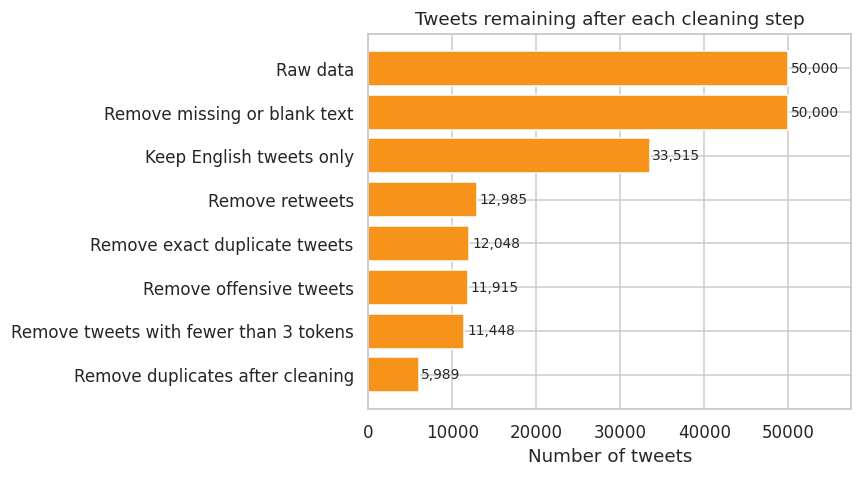

In [ ]:
# Funnel chart of the cleaning steps
log_df = pd.DataFrame(step_log)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(log_df["step"][::-1], log_df["tweets_remaining"][::-1], color="#F7931A")
for i, v in enumerate(log_df["tweets_remaining"][::-1]):
    ax.text(v + 300, i, f"{v:,}", va="center", fontsize=9)
ax.set_title("Tweets remaining after each cleaning step")
ax.set_xlabel("Number of tweets")
ax.set_xlim(0, log_df["tweets_remaining"].max() * 1.15)
plt.tight_layout()
plt.savefig("figures/fig_cleaning_funnel.png", dpi=150)
plt.show()

In [ ]:
# Compare original and cleaned text for 5 random tweets
sample = df.sample(5, random_state=SEED)
for _, row in sample.iterrows():
    print("ORIGINAL:", row["tweet_text"][:220].replace("\n", " "))
    print("CLEANED :", row["clean_text"])
    print()

ORIGINAL: You Can'T Stop This | Bitcoin T-, HODL, Crypto currency, Digital Currency  #t #Crypto #DigitalCurrency #Bitcoin #CantStop #hodl #PlusMinusCo https://t.co/wVMezuqlcY
CLEANED : stop bitcoin hodl crypto currency digital currency crypto digitalcurrency bitcoin cantstop hodl plusminusco

ORIGINAL: Bitcoin is warming lube for CBDCs. #bitcoin #xrp #xlm #gold #silver #dollarmilkshake
CLEANED : bitcoin warming lube cbdc bitcoin xrp xlm gold silver dollarmilkshake

ORIGINAL: Ethereum Classic and Ravencoin have fallen in price after the Merger $BTNYX $BTC $btc #Bitcoin https://t.co/pt4bBCbbUo
CLEANED : ethereum classic ravencoin fallen price merger btnyx btc btc bitcoin

ORIGINAL: #makemoney #earnmoney #affiliatelink #EarnMoneyOnline   #bitcoin #dogecoin #affiliatemarketing Check my website for my top recommended https://t.co/PNmD3GdTEx
CLEANED : makemoney earnmoney affiliatelink earnmoneyonline bitcoin dogecoin affiliatemarketing check website top recommended

ORIGINAL: @SECGov @GaryGe

## 3. Exploratory text analysis
### 3.1 Tweet volume over time (hourly)
The dataset covers about 6.5 hours. We use hourly intervals as requested. The first and last hours are **partial hours** (the data starts at 17:33 and stops at 00:04), so their counts are low.

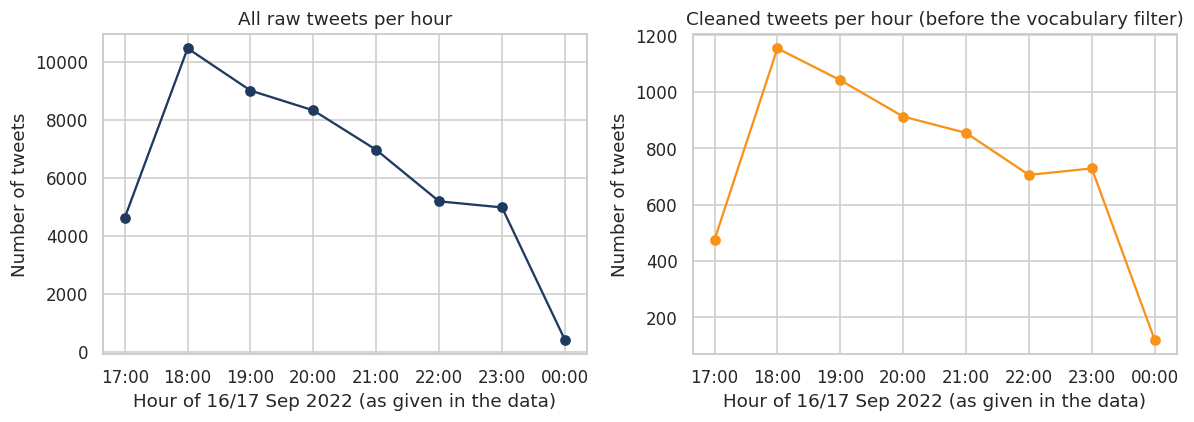

,raw_tweets,cleaned_tweets
2022-09-16 17:00:00,4629,475
2022-09-16 18:00:00,10465,1154
2022-09-16 19:00:00,9011,1041
2022-09-16 20:00:00,8327,912
2022-09-16 21:00:00,6967,854
2022-09-16 22:00:00,5194,705
2022-09-16 23:00:00,4984,728
2022-09-17 00:00:00,423,120


In [ ]:
raw_hourly = (
    pd.to_datetime(raw["Tweet Posted Time"], format="%d %b %Y %H:%M:%S").dt.floor("h").value_counts().sort_index()
)
df["hour"] = df["posted_time"].dt.floor("h")
model_hourly = df["hour"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(raw_hourly.index, raw_hourly.values, marker="o", color="#1F3A5F")
axes[0].set_title("All raw tweets per hour")
axes[1].plot(model_hourly.index, model_hourly.values, marker="o", color="#F7931A")
axes[1].set_title("Cleaned tweets per hour (before the vocabulary filter)")
for ax, series in zip(axes, [raw_hourly, model_hourly]):
    ax.set_xticks(series.index)
    ax.set_xticklabels(series.index.strftime("%H:00"))
    ax.set_ylabel("Number of tweets")
    ax.set_xlabel("Hour of 16/17 Sep 2022 (as given in the data)")
plt.tight_layout()
plt.savefig("figures/fig_hourly_volume.png", dpi=150)
plt.show()
pd.DataFrame({"raw_tweets": raw_hourly, "cleaned_tweets": model_hourly})

### 3.2 Most frequent words and hashtags (word clouds)
Domain words such as bitcoin and btc are **kept**. They are large in the cloud because most tweets mention them.

In [ ]:
word_counts = Counter(t for toks in df["tokens"] for t in toks)
print("Top 20 words:", word_counts.most_common(20))

# Hashtags come from the original text (before cleaning)
hashtag_counts = Counter(
    h.lower() for text in df["tweet_text"] for h in re.findall(r"#(\w+)", text)
    if not h.isdigit()
)
print("Top 20 hashtags:", hashtag_counts.most_common(20))

Top 20 words: [('bitcoin', 6292), ('crypto', 2177), ('btc', 2009), ('cryptocurrency', 1237), ('ethereum', 1103), ('eth', 996), ('nft', 962), ('market', 630), ('binance', 543), ('blockchain', 522), ('price', 497), ('project', 404), ('cryptonews', 400), ('money', 345), ('news', 340), ('bnb', 320), ('altcoin', 318), ('time', 303), ('metaverse', 302), ('buy', 278)]
Top 20 hashtags: [('bitcoin', 5598), ('crypto', 1573), ('btc', 1277), ('cryptocurrency', 906), ('ethereum', 878), ('eth', 703), ('nft', 496), ('binance', 463), ('blockchain', 439), ('cryptonews', 397), ('nfts', 338), ('bnb', 259), ('metaverse', 241), ('defi', 179), ('dogecoin', 171), ('cryptocurrencies', 171), ('altcoin', 171), ('trading', 167), ('web3', 166), ('bsc', 164)]


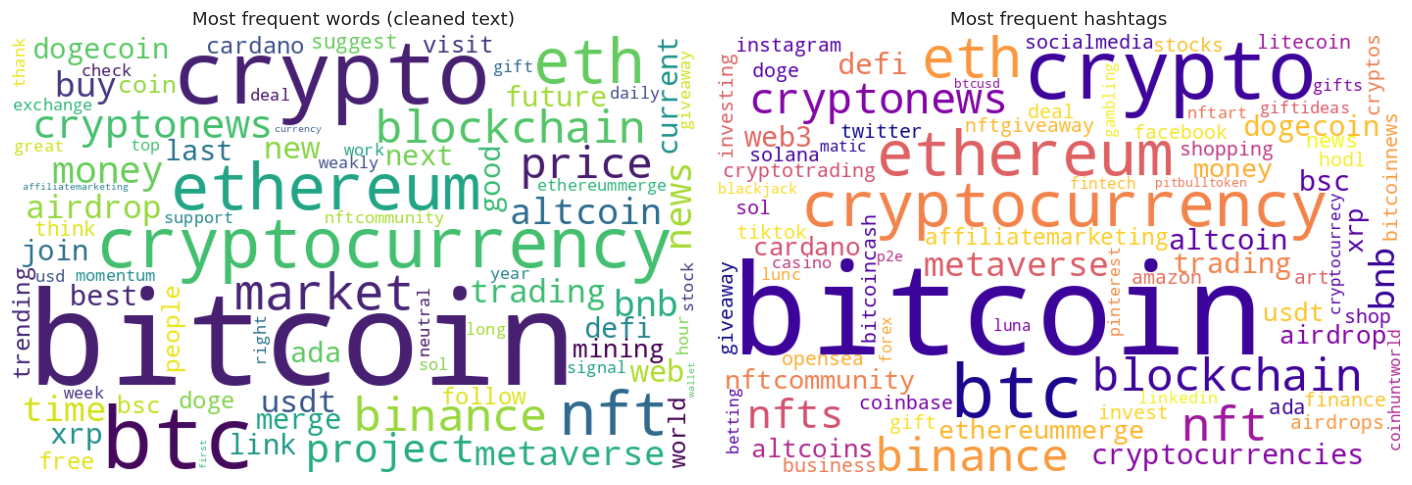

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
wc_words = WordCloud(width=700, height=450, background_color="white", max_words=80,
                     colormap="viridis", random_state=SEED).generate_from_frequencies(word_counts)
wc_tags = WordCloud(width=700, height=450, background_color="white", max_words=80,
                    colormap="plasma", random_state=SEED).generate_from_frequencies(hashtag_counts)
axes[0].imshow(wc_words, interpolation="bilinear"); axes[0].set_title("Most frequent words (cleaned text)")
axes[1].imshow(wc_tags, interpolation="bilinear");  axes[1].set_title("Most frequent hashtags")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("figures/fig_wordclouds.png", dpi=150)
plt.show()

### 3.3 Meaningful bigrams and trigrams
Bigrams are pairs of words that appear together. Trigrams are groups of three. They show phrases that single words hide.

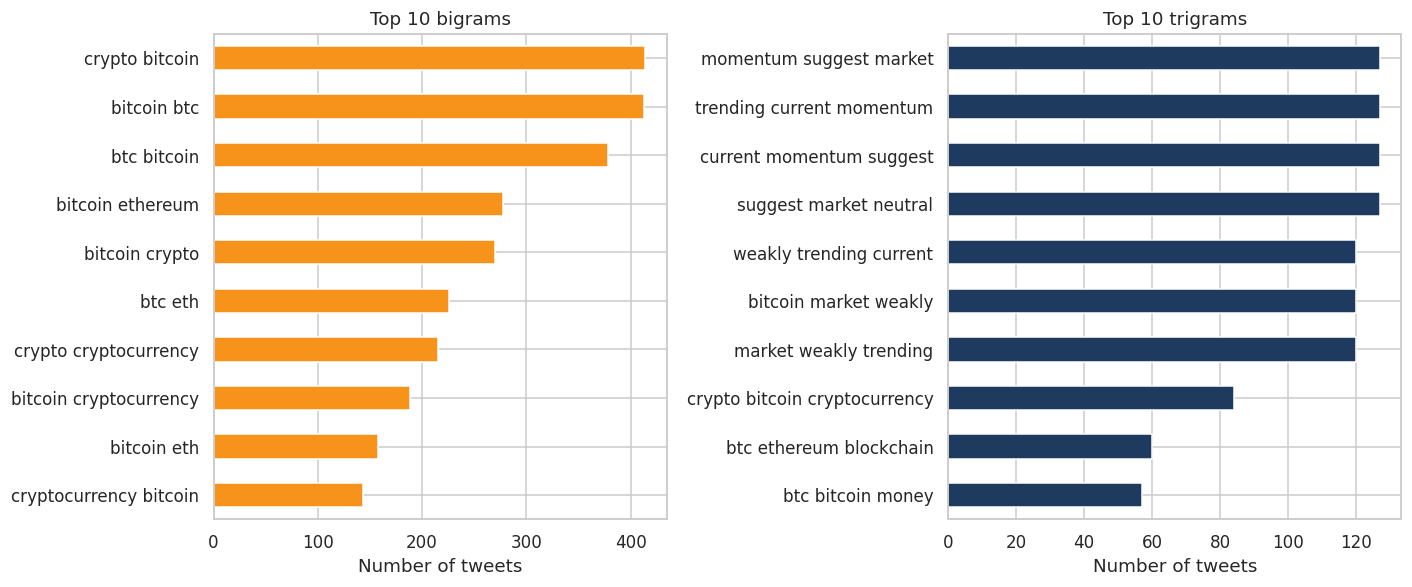

crypto bitcoin            414
bitcoin btc               413
btc bitcoin               378
bitcoin ethereum          278
bitcoin crypto            270
btc eth                   226
crypto cryptocurrency     215
bitcoin cryptocurrency    188
bitcoin eth               158
cryptocurrency bitcoin    143
dtype: int64
momentum suggest market          127
trending current momentum        127
current momentum suggest         127
suggest market neutral           127
weakly trending current          120
bitcoin market weakly            120
market weakly trending           120
crypto bitcoin cryptocurrency     84
btc ethereum blockchain           60
btc bitcoin money                 57
dtype: int64


In [ ]:
def top_ngrams(texts, n, top=10, min_df=5):
    vec = CountVectorizer(ngram_range=(n, n), min_df=min_df)
    mat = vec.fit_transform(texts)
    counts = np.asarray(mat.sum(axis=0)).ravel()
    order = counts.argsort()[::-1][:top]
    names = vec.get_feature_names_out()
    return pd.Series(counts[order], index=names[order])

bigrams = top_ngrams(df["clean_text"], 2)
trigrams = top_ngrams(df["clean_text"], 3)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
bigrams[::-1].plot(kind="barh", ax=axes[0], color="#F7931A")
axes[0].set_title("Top 10 bigrams")
trigrams[::-1].plot(kind="barh", ax=axes[1], color="#1F3A5F")
axes[1].set_title("Top 10 trigrams")
for ax in axes:
    ax.set_xlabel("Number of tweets")
plt.tight_layout()
plt.savefig("figures/fig_ngrams.png", dpi=150)
plt.show()
print(bigrams.head(10))
print(trigrams.head(10))

### 3.4 Additional visualisation: most used hashtags (bar chart) and tweet length
A bar chart gives exact counts, which a word cloud cannot do. The length plot shows how short most cleaned tweets are, which matters for topic models.

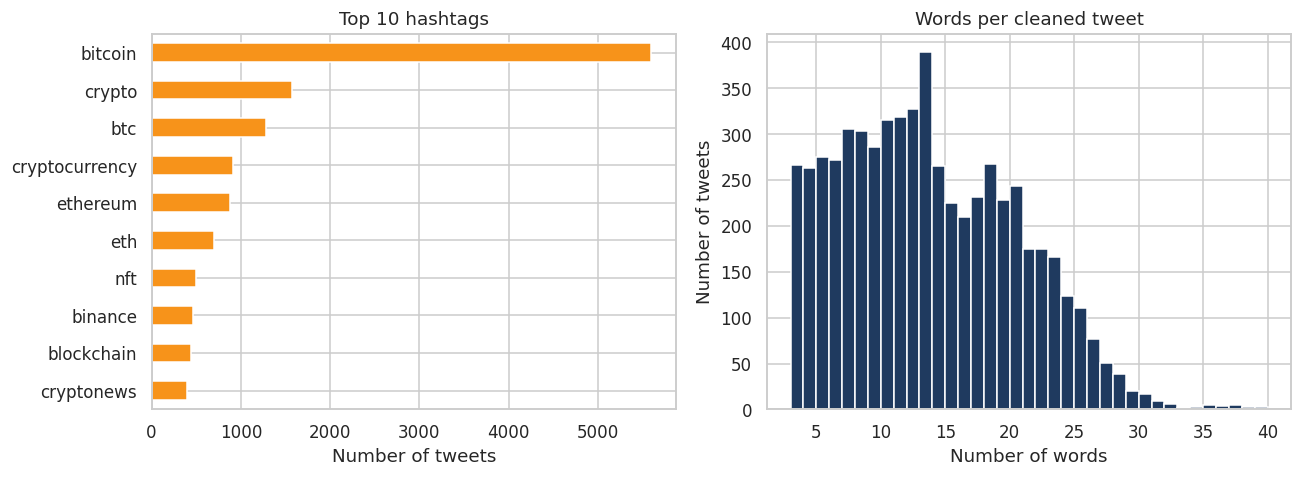

Median words per cleaned tweet: 13.0


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
top_tags = pd.Series(dict(hashtag_counts.most_common(10)))
top_tags[::-1].plot(kind="barh", ax=axes[0], color="#F7931A")
axes[0].set_title("Top 10 hashtags"); axes[0].set_xlabel("Number of tweets")
axes[1].hist(df["n_tokens"], bins=range(3, 41), color="#1F3A5F", edgecolor="white")
axes[1].set_title("Words per cleaned tweet"); axes[1].set_xlabel("Number of words"); axes[1].set_ylabel("Number of tweets")
plt.tight_layout()
plt.savefig("figures/fig_hashtags_length.png", dpi=150)
plt.show()
print("Median words per cleaned tweet:", df["n_tokens"].median())

## 4. Text representation
Topic models need numbers, not text. We turn the cleaned tweets into a **document-term matrix** (rows are tweets, columns are words).

- **LDA** works with raw word **counts** (CountVectorizer)
- **NMF** works well with **TF-IDF** weights (TfidfVectorizer). TF-IDF gives a higher weight to words that are special to a tweet and a lower weight to words that appear everywhere.

Vectoriser settings (same for both):
- `min_df=5`: ignore words found in fewer than 5 tweets (rare words and typos)
- `max_df=0.5`: ignore words found in more than 50% of tweets. This only affects words that appear in almost every tweet (see below).
- `max_features=3000`: keep the 3000 most common remaining words

In [ ]:
# Which words are in more than 50% of tweets? (bitcoin and btc usually)
binary_vec = CountVectorizer(binary=True, min_df=5)
B = binary_vec.fit_transform(df["clean_text"])
doc_freq = pd.Series(np.asarray(B.sum(axis=0)).ravel() / B.shape[0], index=binary_vec.get_feature_names_out())
print("Words found in more than 50% of tweets:")
print(doc_freq[doc_freq > 0.5].sort_values(ascending=False).round(3))
print()
print("Next 10 most common words (still kept):")
print(doc_freq[doc_freq <= 0.5].sort_values(ascending=False).head(10).round(3))

Words found in more than 50% of tweets:
bitcoin    0.918
dtype: float64

Next 10 most common words (still kept):
crypto            0.303
btc               0.277
cryptocurrency    0.174
ethereum          0.170
eth               0.155
nft               0.124
binance           0.086
blockchain        0.080
market            0.077
price             0.072
dtype: float64


**Decision on frequent domain words.** The assignment says not to remove domain terms just because they are frequent. We keep `bitcoin` and `btc` in the cleaned text, in the word clouds and in the n-gram analysis. For the topic models only, `max_df=0.5` automatically ignores any word that appears in more than half of all tweets. We do this because a word found in nearly every tweet cannot separate one topic from another, and it would appear at the top of every topic. This is a documented choice and not a manual deletion. All other domain words (price, trading, mining, bullish, bearish and so on) are kept.

In [ ]:
VEC_PARAMS = dict(min_df=5, max_df=0.5, max_features=3000)

# First pass: find tweets that have at least 3 words left in the vocabulary
tmp = CountVectorizer(**VEC_PARAMS).fit(df["clean_text"])
vocab_len = np.asarray(tmp.transform(df["clean_text"]).sum(axis=1)).ravel()
print("Tweets with fewer than 3 vocabulary words:", int((vocab_len < 3).sum()))
df_model = df[vocab_len >= 3].reset_index(drop=True)
print("Final modelling dataset:", df_model.shape)

# Final matrices on the final modelling dataset
count_vec = CountVectorizer(**VEC_PARAMS)
X_count = count_vec.fit_transform(df_model["clean_text"])          # for LDA

tfidf_vec = TfidfVectorizer(**VEC_PARAMS)
X_tfidf = tfidf_vec.fit_transform(df_model["clean_text"])          # for NMF

feature_names = count_vec.get_feature_names_out()
assert list(feature_names) == list(tfidf_vec.get_feature_names_out())

print("Count matrix :", X_count.shape, "| non-zero share:", round(X_count.nnz / np.prod(X_count.shape) * 100, 3), "%")
print("TF-IDF matrix:", X_tfidf.shape, "| non-zero share:", round(X_tfidf.nnz / np.prod(X_tfidf.shape) * 100, 3), "%")

Tweets with fewer than 3 vocabulary words: 462
Final modelling dataset: (5527, 11)
Count matrix : (5527, 2205) | non-zero share: 0.457 %
TF-IDF matrix: (5527, 2205) | non-zero share: 0.457 %


In [ ]:
# Compare the two representations: top words by total count and by total TF-IDF weight
total_count = pd.Series(np.asarray(X_count.sum(axis=0)).ravel(), index=feature_names).sort_values(ascending=False)
total_tfidf = pd.Series(np.asarray(X_tfidf.sum(axis=0)).ravel(), index=feature_names).sort_values(ascending=False)
pd.DataFrame({
    "top_by_count": total_count.head(12).index,
    "count": total_count.head(12).values,
    "top_by_tfidf": total_tfidf.head(12).index,
    "tfidf_weight": total_tfidf.head(12).values.round(1),
})

,top_by_count,count,top_by_tfidf,tfidf_weight
0,crypto,2174,crypto,254.9
1,btc,1983,btc,247.3
2,cryptocurrency,1233,cryptocurrency,182.3
3,ethereum,1095,ethereum,167.2
4,eth,989,nft,146.7
5,nft,958,eth,146.5
6,market,628,market,122.1
7,binance,543,binance,100.4
8,blockchain,519,blockchain,96.5
9,price,492,price,93.9


### 4.1 Final modelling dataset (documentation)
This is the dataset that goes into the topic models. Each row is one cleaned, English, non-retweet, non-offensive, unique tweet.

In [ ]:
df_model["hour"] = df_model["posted_time"].dt.floor("h")
final_dataset_doc = pd.DataFrame({
    "variable": ["tweet_id", "posted_time", "tweet_text", "clean_text", "n_tokens", "hour"],
    "type": [str(df_model[c].dtype) for c in ["tweet_id", "posted_time", "tweet_text", "clean_text", "n_tokens", "hour"]],
    "meaning": [
        "Unique tweet identifier (kept as text)",
        "Date and time the tweet was posted",
        "Original tweet text (kept so we can show real examples)",
        "Cleaned text: lowercase words, no stop words, lemmatised",
        "Number of words left after cleaning",
        "Posted time rounded down to the hour (for the hourly plots)",
    ],
})
print("Rows in final modelling dataset:", len(df_model))
print("Vocabulary size (columns of the matrices):", len(feature_names))
print("Time range:", df_model["posted_time"].min(), "to", df_model["posted_time"].max())
final_dataset_doc

Rows in final modelling dataset: 5527
Vocabulary size (columns of the matrices): 2205
Time range: 2022-09-16 17:33:49 to 2022-09-17 00:04:48


,variable,type,meaning
0,tweet_id,object,Unique tweet identifier (kept as text)
1,posted_time,datetime64[ns],Date and time the tweet was posted
2,tweet_text,object,Original tweet text (kept so we can show real ...
3,clean_text,object,"Cleaned text: lowercase words, no stop words, ..."
4,n_tokens,int64,Number of words left after cleaning
5,hour,datetime64[ns],Posted time rounded down to the hour (for the ...


## 5. Topic modelling and model comparison
We train two topic models on the same cleaned tweets:

| Model | Input | Idea |
|---|---|---|
| **LDA** (Latent Dirichlet Allocation) | word counts | Each tweet is a mix of topics. Each topic is a mix of words (probabilities). |
| **NMF** (Non-negative Matrix Factorisation) | TF-IDF | Splits the matrix into two non-negative parts: tweet-topic weights and topic-word weights. |

We test **k = 4, 5, 6, 7, 8** topics for each model with `random_state=42`.

### How we judge topic quality (three kinds of evidence)
1. **Topic coherence (NPMI):** do the top words of a topic appear together in the same tweets? Higher is better (range -1 to 1). We calculate it ourselves on this corpus using tweet-level co-occurrence.
2. **Topic diversity:** share of unique words among all top-10 word lists. 1.0 means no word is repeated across topics. Higher is better.
3. **Human interpretability:** can a person give each topic a clear name by reading its top words? We score this after reading the topics.

In [ ]:
K_LIST = [4, 5, 6, 7, 8]
N_TOP = 10

# Helper 1: top words of each topic
def get_top_idx(components, n=N_TOP):
    return [row.argsort()[::-1][:n] for row in components]

def idx_to_words(idx_lists):
    return [[feature_names[i] for i in idx] for idx in idx_lists]

# Helper 2: NPMI coherence using tweet-level co-occurrence
B_bin = (X_count > 0).astype(np.float64).tocsr()
n_docs = B_bin.shape[0]
word_df = np.asarray(B_bin.sum(axis=0)).ravel()
co_occur = (B_bin.T @ B_bin).toarray()

def npmi_coherence(idx_lists):
    topic_scores = []
    for idx in idx_lists:
        pair_scores = []
        for a in range(len(idx)):
            for b in range(a + 1, len(idx)):
                i, j = idx[a], idx[b]
                p_ij = co_occur[i, j] / n_docs
                if p_ij == 0:
                    pair_scores.append(-1.0)
                else:
                    p_i, p_j = word_df[i] / n_docs, word_df[j] / n_docs
                    pair_scores.append(np.log(p_ij / (p_i * p_j)) / (-np.log(p_ij)))
        topic_scores.append(np.mean(pair_scores))
    return topic_scores

# Helper 3: topic diversity
def topic_diversity(idx_lists):
    all_words = [i for idx in idx_lists for i in idx]
    return len(set(all_words)) / len(all_words)

# Helper 4: model builders
def fit_lda(k, seed):
    return LatentDirichletAllocation(n_components=k, learning_method="batch", max_iter=40,
                                     random_state=seed, n_jobs=1).fit(X_count)

def fit_nmf(k, seed):
    return NMF(n_components=k, init="random", random_state=seed, max_iter=500, tol=1e-4).fit(X_tfidf)

print("Helpers ready.")

Helpers ready.


In [ ]:
# Train all 10 models (2 methods x 5 values of k) with random_state = 42
models, results = {}, []
for method, builder in [("LDA", fit_lda), ("NMF", fit_nmf)]:
    for k in K_LIST:
        model = builder(k, SEED)
        idx = get_top_idx(model.components_)
        coh = npmi_coherence(idx)
        models[(method, k)] = model
        results.append({"model": method, "k": k,
                        "coherence_npmi": round(float(np.mean(coh)), 4),
                        "min_topic_coherence": round(float(np.min(coh)), 4),
                        "diversity": round(topic_diversity(idx), 3)})
        print(f"done {method} k={k}")

scores = pd.DataFrame(results)
scores

done LDA k=4
done LDA k=5
done LDA k=6
done LDA k=7
done LDA k=8
done NMF k=4
done NMF k=5
done NMF k=6
done NMF k=7
done NMF k=8


,model,k,coherence_npmi,min_topic_coherence,diversity
0,LDA,4,0.0441,-0.0402,0.775
1,LDA,5,0.0967,-0.0402,0.820
2,LDA,6,0.1718,-0.0069,0.767
3,LDA,7,0.1723,-0.0906,0.743
4,LDA,8,0.1929,-0.1432,0.700
5,NMF,4,0.3322,0.1631,0.950
6,NMF,5,0.3128,0.1631,0.940
7,NMF,6,0.3656,0.1631,0.933
8,NMF,7,0.3823,0.2200,0.914
9,NMF,8,0.4400,0.2200,0.925


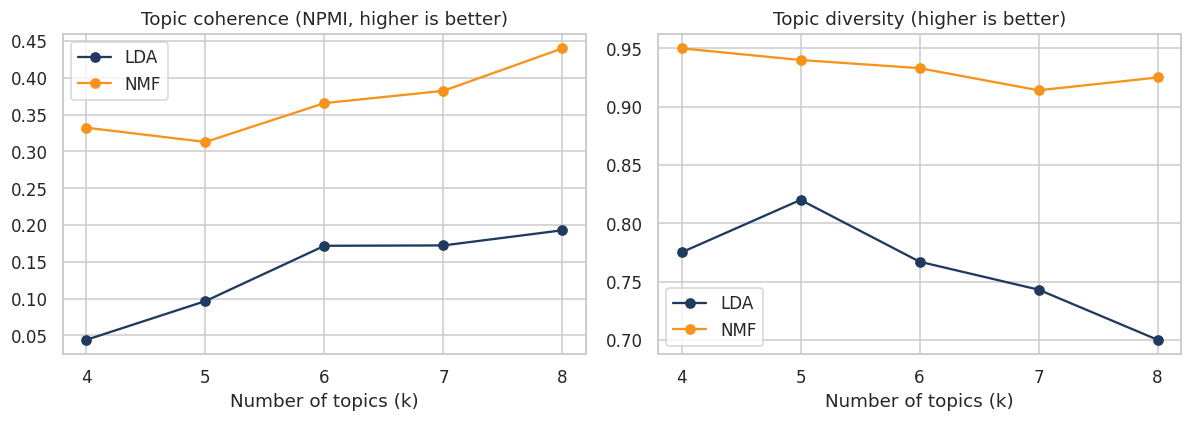

In [ ]:
# Plot coherence and diversity for each k
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for method, colour in [("LDA", "#1F3A5F"), ("NMF", "#F7931A")]:
    part = scores[scores["model"] == method]
    axes[0].plot(part["k"], part["coherence_npmi"], marker="o", label=method, color=colour)
    axes[1].plot(part["k"], part["diversity"], marker="o", label=method, color=colour)
axes[0].set_title("Topic coherence (NPMI, higher is better)")
axes[1].set_title("Topic diversity (higher is better)")
for ax in axes:
    ax.set_xlabel("Number of topics (k)")
    ax.set_xticks(K_LIST)
    ax.legend()
plt.tight_layout()
plt.savefig("figures/fig_model_comparison.png", dpi=150)
plt.show()

### 5.1 Human interpretability: read the topics
We print the top 10 words of every topic for every model, so we can judge whether a person can name each topic.

In [ ]:
for (method, k), model in models.items():
    words = idx_to_words(get_top_idx(model.components_))
    print(f"===== {method}, k = {k} =====")
    for t, w in enumerate(words):
        print(f"  Topic {t}: {', '.join(w)}")
    print()

===== LDA, k = 4 =====
  Topic 0: dogecoin, gift, deal, money, affiliatemarketing, work, usd, sat, instagram, facebook
  Topic 1: btc, time, crypto, market, buy, price, people, new, next, mining
  Topic 2: crypto, btc, cryptocurrency, project, airdrop, ethereum, eth, cryptonews, future, price
  Topic 3: crypto, btc, ethereum, nft, eth, cryptocurrency, binance, blockchain, market, news

===== LDA, k = 5 =====
  Topic 0: dogecoin, gift, deal, work, affiliatemarketing, usd, money, sat, instagram, facebook
  Topic 1: btc, time, buy, price, next, last, long, year, people, pit
  Topic 2: project, crypto, btc, cryptocurrency, airdrop, good, best, money, future, great
  Topic 3: crypto, btc, nft, ethereum, eth, cryptocurrency, binance, blockchain, altcoin, cryptonews
  Topic 4: market, crypto, current, btc, visit, price, trending, ethereum, suggest, neutral

===== LDA, k = 6 =====
  Topic 0: dogecoin, gift, deal, affiliatemarketing, work, instagram, facebook, socialmedia, tiktok, shop
  Topic 

### 5.2 Score human interpretability and choose the final model
We read the topic lists above and gave each model a score from 1 to 5:
- **1** = we cannot give the topics clear names
- **3** = about half of the topics have clear names, the rest are mixed or vague
- **5** = every topic has a clear, different name

This is a human judgement, so **the group should read the lists above and change these scores if they disagree.** Our reasons are in the report.

Then we combine the three evidence scores. Each score is rescaled to 0 to 1 (0 is the worst of the 10 models, 1 is the best), and we take the average.

In [ ]:
# EDIT these scores if your group reads the topics differently
interpretability = {
    ("LDA", 4): 2.0, ("LDA", 5): 2.5, ("LDA", 6): 3.0, ("LDA", 7): 3.0, ("LDA", 8): 3.0,
    ("NMF", 4): 3.0, ("NMF", 5): 3.5, ("NMF", 6): 3.5, ("NMF", 7): 4.0, ("NMF", 8): 4.5,
}
scores["interpretability"] = [interpretability[(m, k)] for m, k in zip(scores["model"], scores["k"])]

def rescale(s):
    return (s - s.min()) / (s.max() - s.min())

scores["combined_score"] = (rescale(scores["coherence_npmi"]) + rescale(scores["diversity"]) +
                            rescale(scores["interpretability"])).div(3).round(3)

scores_sorted = scores.sort_values("combined_score", ascending=False).reset_index(drop=True)
best = scores_sorted.iloc[0]
FINAL_METHOD, FINAL_K = best["model"], int(best["k"])
print(f"Selected model: {FINAL_METHOD} with k = {FINAL_K}")
scores_sorted

Selected model: NMF with k = 8


,model,k,coherence_npmi,min_topic_coherence,diversity,interpretability,combined_score
0,NMF,8,0.4400,0.2200,0.925,4.5,0.967
1,NMF,7,0.3823,0.2200,0.914,4.0,0.837
2,NMF,6,0.3656,0.1631,0.933,3.5,0.781
3,NMF,5,0.3128,0.1631,0.940,3.5,0.746
4,NMF,4,0.3322,0.1631,0.950,3.0,0.709
5,LDA,6,0.1718,-0.0069,0.767,3.0,0.330
6,LDA,7,0.1723,-0.0906,0.743,3.0,0.299
7,LDA,5,0.0967,-0.0402,0.820,2.5,0.271
8,LDA,8,0.1929,-0.1432,0.700,3.0,0.259
9,LDA,4,0.0441,-0.0402,0.775,2.0,0.100


### 5.3 Stability check with a different random seed
We train the selected model again with `random_state=7`. Then we match each topic from seed 42 to its closest topic from seed 7 (using cosine similarity of the word weights) and compare the top words. If the same themes come back, the result is reasonably stable.

In [ ]:
model_42 = models[(FINAL_METHOD, FINAL_K)]
model_7 = fit_nmf(FINAL_K, 7) if FINAL_METHOD == "NMF" else fit_lda(FINAL_K, 7)

def unit_rows(m):
    return m / np.linalg.norm(m, axis=1, keepdims=True)

similarity = unit_rows(model_42.components_) @ unit_rows(model_7.components_).T
rows_42, cols_7 = linear_sum_assignment(-similarity)      # best one-to-one match

words_42 = idx_to_words(get_top_idx(model_42.components_))
words_7 = idx_to_words(get_top_idx(model_7.components_))

stability = pd.DataFrame({
    "topic_seed42": rows_42,
    "top_words_seed42": [", ".join(words_42[i][:6]) for i in rows_42],
    "matched_topic_seed7": cols_7,
    "top_words_seed7": [", ".join(words_7[j][:6]) for j in cols_7],
    "cosine_similarity": [round(similarity[i, j], 3) for i, j in zip(rows_42, cols_7)],
    "shared_top10_words": [len(set(words_42[i]) & set(words_7[j])) for i, j in zip(rows_42, cols_7)],
})
pd.set_option("display.max_colwidth", 80)
print("Average cosine similarity:", round(stability["cosine_similarity"].mean(), 3))
print("Average shared top-10 words:", stability["shared_top10_words"].mean())
idx7 = get_top_idx(model_7.components_)
print("Seed 7 coherence:", round(float(np.mean(npmi_coherence(idx7))), 4), "| diversity:", round(topic_diversity(idx7), 3))
stability

Average cosine similarity: 0.892
Average shared top-10 words: 8.25
Seed 7 coherence: 0.3841 | diversity: 0.963


,topic_seed42,top_words_seed42,matched_topic_seed7,top_words_seed7,cosine_similarity,shared_top10_words
0,0,"crypto, cryptocurrency, ethereum, cryptonews, blockchain, eth",0,"crypto, cryptocurrency, ethereum, cryptonews, blockchain, eth",0.985,8
1,1,"project, airdrop, good, future, great, best",7,"project, airdrop, good, future, great, best",0.999,10
2,2,"market, neutral, momentum, suggest, trending, visit",4,"market, neutral, momentum, suggest, trending, visit",1.000,10
3,3,"nft, metaverse, art, ethereum, binance, opensea",5,"nft, metaverse, art, ethereum, opensea, nftcommunity",0.980,9
4,4,"gift, deal, affiliatemarketing, dogecoin, socialmedia, facebook",3,"gift, deal, affiliatemarketing, dogecoin, socialmedia, facebook",1.000,10
5,5,"awesome, coinhuntworld, location, vault, join, found",2,"awesome, coinhuntworld, location, vault, join, found",1.000,10
6,6,"btc, eth, bnb, price, ada, binance",1,"btc, price, eth, bnb, ada, usd",0.958,7
7,7,"price, signal, usdt, chng, volume, last",6,"binance, altcoin, trading, buy, minute, went",0.214,2


## 6. Topic analysis (final model)
### 6.1 Keywords and example tweets
We use the selected model (seed 42). The topic names below are **our interpretation**. They are not true labels. The model only gives groups of words.

{0: 'Crypto news and the Ethereum Merge', 1: 'Airdrops and new projects', 2: 'Automated market momentum alerts', 3: 'NFTs and the metaverse', 4: 'Gift deals and social media marketing', 5: 'Crypto game promotion', 6: 'Coin prices and tickers', 7: 'Price signals and volume alerts'}


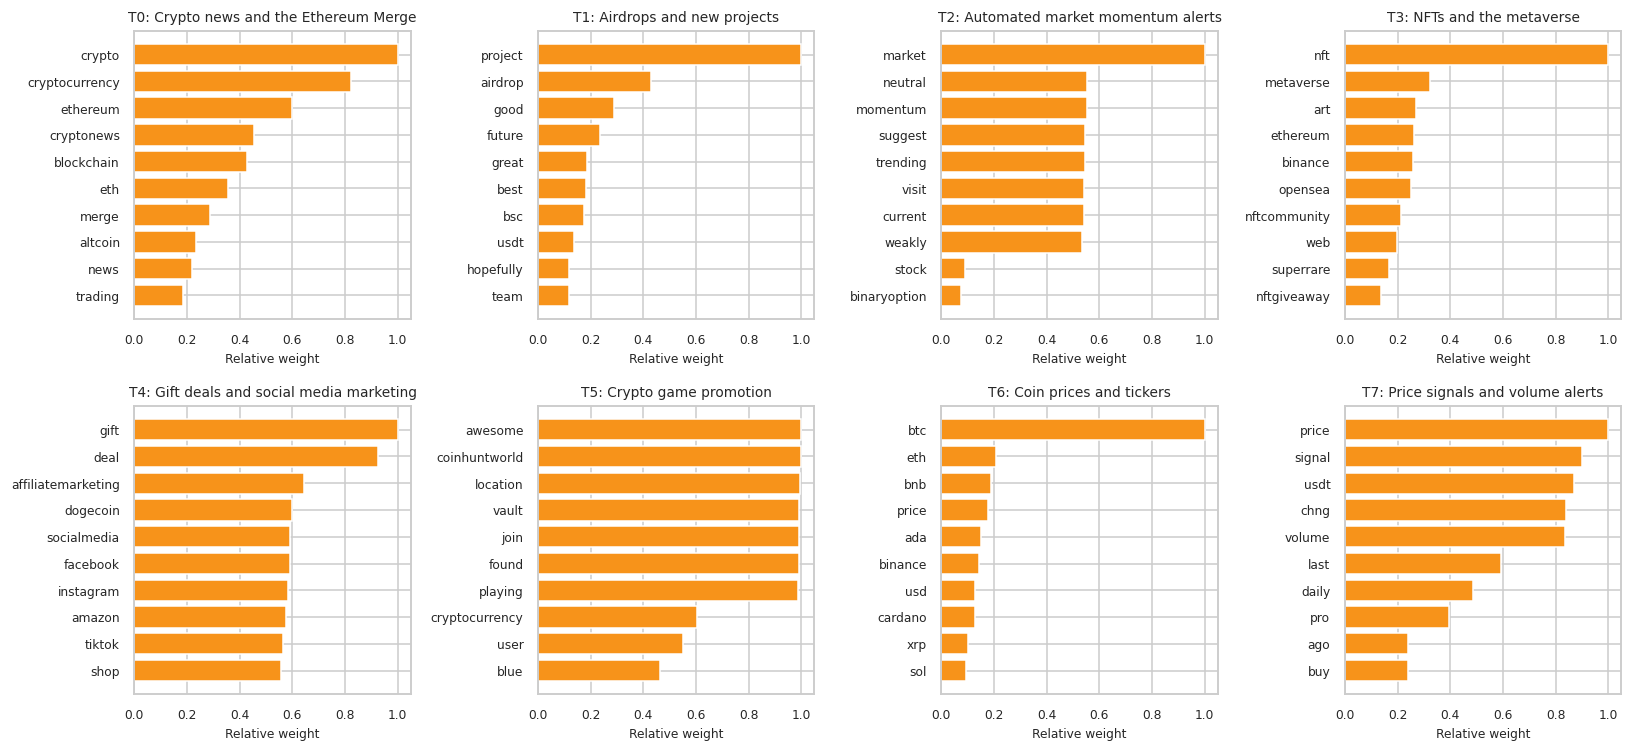

In [ ]:
final_model = model_42
top_idx = get_top_idx(final_model.components_)
top_words = idx_to_words(top_idx)

# Topic names. We find each topic by one signature word in its top-10 list, so the names stay correct
# even if the topic numbers change on another computer.
signature_to_name = {
    "cryptonews":        "Crypto news and the Ethereum Merge",
    "airdrop":           "Airdrops and new projects",
    "neutral":           "Automated market momentum alerts",
    "nft":               "NFTs and the metaverse",
    "affiliatemarketing":"Gift deals and social media marketing",
    "coinhuntworld":     "Crypto game promotion",
    "cardano":           "Coin prices and tickers",
    "chng":              "Price signals and volume alerts",
}
topic_names = {}
for t, words in enumerate(top_words):
    topic_names[t] = next((name for sig, name in signature_to_name.items() if sig in words), f"Topic {t}")
print(topic_names)

# Figure: top 10 words per topic
n_topics = FINAL_K
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for t, ax in enumerate(axes.ravel()):
    weights = final_model.components_[t][top_idx[t]]
    ax.barh(top_words[t][::-1], weights[::-1] / weights.max(), color="#F7931A")
    ax.set_title(f"T{t}: {topic_names[t]}", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.set_xlabel("Relative weight", fontsize=8)
plt.tight_layout()
plt.savefig("figures/fig_topic_words.png", dpi=150)
plt.show()

In [ ]:
# Document-topic matrix: how much each tweet belongs to each topic (rows add up to 1)
raw_weights = final_model.transform(X_tfidf if FINAL_METHOD == "NMF" else X_count)
row_sum = raw_weights.sum(axis=1, keepdims=True)
doc_topic = np.where(row_sum > 0, raw_weights / np.where(row_sum == 0, 1, row_sum), 1.0 / FINAL_K)

df_model["topic"] = doc_topic.argmax(axis=1)
df_model["topic_score"] = doc_topic.max(axis=1).round(4)
df_model["topic_name"] = df_model["topic"].map(topic_names)
print("Tweets with all-zero topic weights (given equal share):", int((row_sum == 0).sum()))
df_model[["tweet_id", "topic", "topic_name", "topic_score"]].head()

Tweets with all-zero topic weights (given equal share): 0


,tweet_id,topic,topic_name,topic_score
0,1570828313199017984,1,Airdrops and new projects,0.4858
1,1570828320958447617,7,Price signals and volume alerts,0.4788
2,1570828344710795270,6,Coin prices and tickers,0.9436
3,1570828354458386434,3,NFTs and the metaverse,0.8378
4,1570828361269936129,6,Coin prices and tickers,1.0000


In [ ]:
# Two example tweets per topic: highest topic score among tweets with at least 6 words, different texts
def clip(text, n=230):
    text = re.sub(r"[\u2013\u2014]", "-", text)          # replace long dashes in tweet text with a hyphen
    text = re.sub(r"\s+", " ", text).strip()
    return text if len(text) <= n else text[:n] + "..."

example_rows = []
for t in range(FINAL_K):
    pool = df_model[(df_model["topic"] == t) & (df_model["n_tokens"] >= 6)].sort_values("topic_score", ascending=False)
    chosen, seen = [], set()
    for _, r in pool.iterrows():
        key = r["clean_text"][:25]
        if key not in seen:
            chosen.append(r); seen.add(key)
        if len(chosen) == 2:
            break
    for r in chosen:
        example_rows.append({"topic": t, "topic_name": topic_names[t], "score": r["topic_score"], "tweet": clip(r["tweet_text"])})

examples = pd.DataFrame(example_rows)
for t in range(FINAL_K):
    print(f"--- Topic {t}: {topic_names[t]} ---")
    print("Keywords:", ", ".join(top_words[t]))
    for _, r in examples[examples["topic"] == t].iterrows():
        print(f"  [score {r['score']}] {r['tweet']}")
    print()

--- Topic 0: Crypto news and the Ethereum Merge ---
Keywords: crypto, cryptocurrency, ethereum, cryptonews, blockchain, eth, merge, altcoin, news, trading
  [score 1.0] Biden Administration Releases Framework for Crypto Regulation - CNET https://t.co/BzSVED9YU3 #crypto #bitcoin #cryptocurrency #blockchain #ethereum
  [score 1.0] How I Became A Crypto Billionaire In 5 Years - YouTube https://t.co/PTLPneZwA1 #crypto #bitcoin #cryptocurrency #blockchain #ethereum

--- Topic 1: Airdrops and new projects ---
Keywords: project, airdrop, good, future, great, best, bsc, usdt, hopefully, team
  [score 1.0] Good project and congratulations to the whole team for their efforts and dedication and commitment. Thanks for giving this opportunity. 😉 @Afnan36373126 @Mdriyad74833142 @bubumoeh
  [score 1.0] Thanks for giving us such a great opportunity. I am supporting it. always success. Impresive and great project. I trust this project can be successfully.😉 @Mdriyad74833142 @MohiburRiyad @kaushik_1413



### 6.2 Share of tweets in each topic
Each tweet goes to its **dominant topic** (the topic with the highest weight).

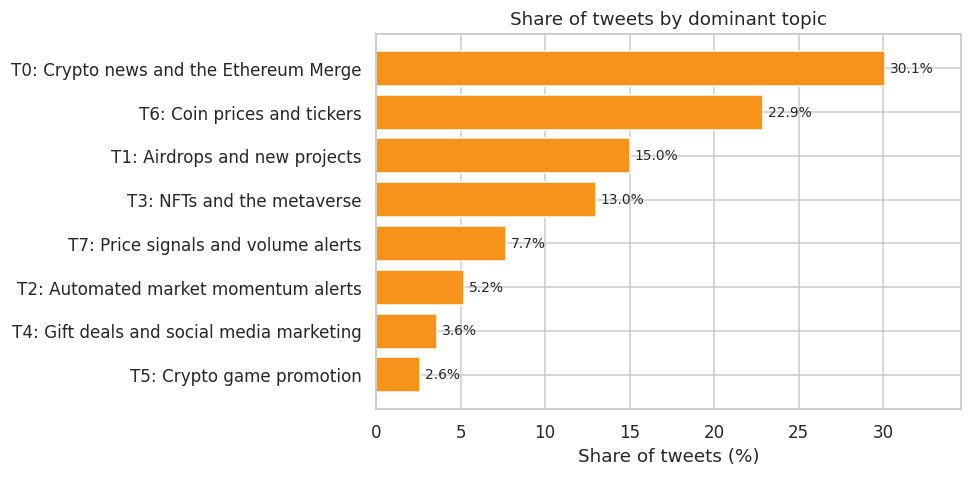

,topic,topic_name,tweets,avg_score,share_percent,top_words
0,0,Crypto news and the Ethereum Merge,1661,0.609,30.1,"crypto, cryptocurrency, ethereum, cryptonews, blockchain"
1,1,Airdrops and new projects,827,0.634,15.0,"project, airdrop, good, future, great"
2,2,Automated market momentum alerts,290,0.730,5.2,"market, neutral, momentum, suggest, trending"
3,3,NFTs and the metaverse,718,0.619,13.0,"nft, metaverse, art, ethereum, binance"
4,4,Gift deals and social media marketing,197,0.709,3.6,"gift, deal, affiliatemarketing, dogecoin, socialmedia"
5,5,Crypto game promotion,141,0.692,2.6,"awesome, coinhuntworld, location, vault, join"
6,6,Coin prices and tickers,1267,0.613,22.9,"btc, eth, bnb, price, ada"
7,7,Price signals and volume alerts,426,0.574,7.7,"price, signal, usdt, chng, volume"


In [ ]:
share = (df_model.groupby(["topic", "topic_name"]).agg(tweets=("tweet_id", "count"), avg_score=("topic_score", "mean")).reset_index())
share["share_percent"] = (share["tweets"] / share["tweets"].sum() * 100).round(1)
share["avg_score"] = share["avg_score"].round(3)
share["top_words"] = [", ".join(top_words[t][:5]) for t in share["topic"]]

fig, ax = plt.subplots(figsize=(9, 4.5))
order = share.sort_values("share_percent")
ax.barh([f"T{t}: {n}" for t, n in zip(order["topic"], order["topic_name"])], order["share_percent"], color="#F7931A")
for i, v in enumerate(order["share_percent"]):
    ax.text(v + 0.3, i, f"{v}%", va="center", fontsize=9)
ax.set_xlabel("Share of tweets (%)")
ax.set_title("Share of tweets by dominant topic")
ax.set_xlim(0, order["share_percent"].max() * 1.15)
plt.tight_layout()
plt.savefig("figures/fig_topic_share.png", dpi=150)
plt.show()
share

### 6.3 Topic prevalence by hour
For each hour we calculate the percentage of tweets that belong to each topic. The first hour (17:00) and the last hour (00:00) are partial hours, so we read them with care.

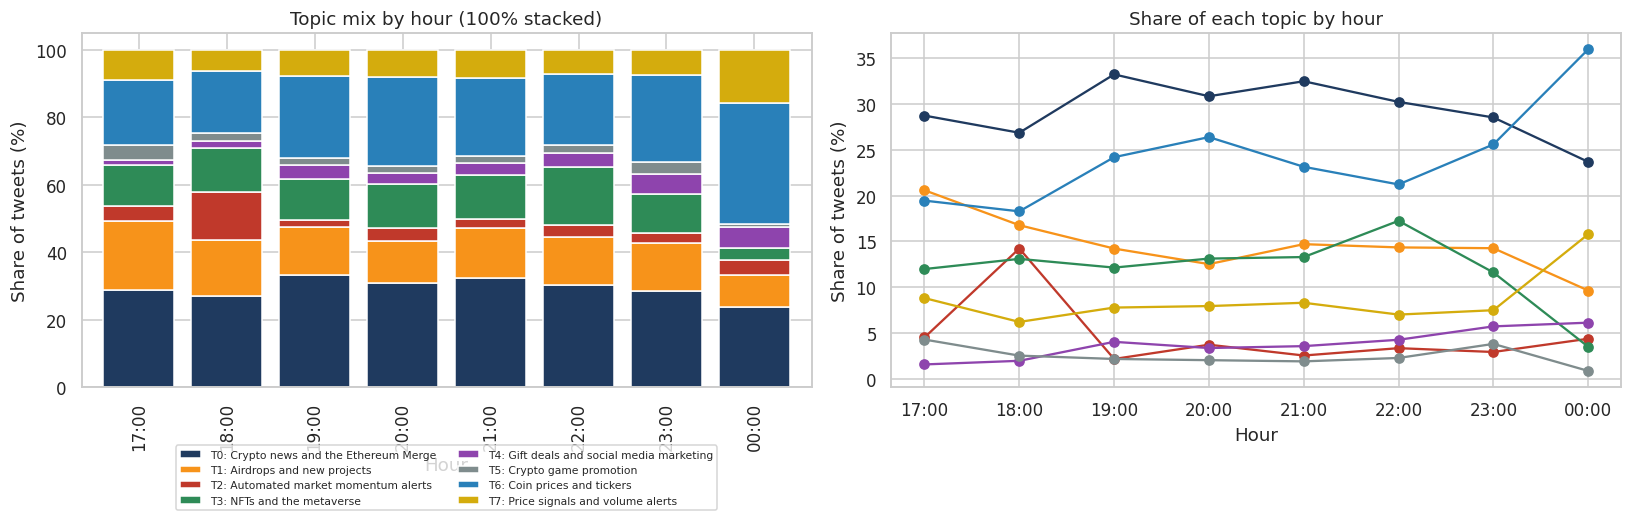

,T0: Crypto news and the Ethereum Merge,T1: Airdrops and new projects,T2: Automated market momentum alerts,T3: NFTs and the metaverse,T4: Gift deals and social media marketing,T5: Crypto game promotion,T6: Coin prices and tickers,T7: Price signals and volume alerts
hour,,,,,,,,
17:00,28.7,20.6,4.5,12.0,1.6,4.3,19.5,8.8
18:00,26.9,16.8,14.2,13.1,2.0,2.5,18.3,6.2
19:00,33.2,14.2,2.2,12.1,4.0,2.2,24.2,7.8
20:00,30.8,12.5,3.7,13.1,3.4,2.0,26.4,8.0
21:00,32.5,14.7,2.6,13.3,3.6,1.9,23.1,8.3
22:00,30.2,14.4,3.4,17.3,4.3,2.3,21.2,7.0
23:00,28.5,14.3,2.9,11.6,5.7,3.8,25.6,7.5
00:00,23.7,9.6,4.4,3.5,6.1,0.9,36.0,15.8


In [ ]:
df_model["hour"] = df_model["posted_time"].dt.floor("h")
hour_counts = pd.crosstab(df_model["hour"], df_model["topic"])
hour_share = hour_counts.div(hour_counts.sum(axis=1), axis=0) * 100
hour_share.columns = [f"T{t}: {topic_names[t]}" for t in hour_share.columns]
hour_share.index = hour_share.index.strftime("%H:00")

palette = ["#1F3A5F", "#F7931A", "#C0392B", "#2E8B57", "#8E44AD", "#7F8C8D", "#2980B9", "#D4AC0D"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
hour_share.plot(kind="bar", stacked=True, ax=axes[0], color=palette, width=0.8)
axes[0].set_title("Topic mix by hour (100% stacked)")
axes[0].set_ylabel("Share of tweets (%)"); axes[0].set_xlabel("Hour")
axes[0].legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
for col, colour in zip(hour_share.columns, palette):
    axes[1].plot(hour_share.index, hour_share[col], marker="o", label=col, color=colour)
axes[1].set_title("Share of each topic by hour")
axes[1].set_ylabel("Share of tweets (%)"); axes[1].set_xlabel("Hour")
plt.tight_layout()
plt.savefig("figures/fig_topic_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()
hour_share.round(1)

In [ ]:
# Change between the first full hour (18:00) and the last full hour (23:00), in percentage points
full = hour_share.loc[["18:00", "23:00"]]
change = (full.loc["23:00"] - full.loc["18:00"]).round(1).sort_values()
print("Change in share from 18:00 to 23:00 (percentage points):")
print(change)
print()
print("Tweets per hour in the modelling data:")
print(hour_counts.sum(axis=1))

Change in share from 18:00 to 23:00 (percentage points):
T2: Automated market momentum alerts        -11.3
T1: Airdrops and new projects                -2.5
T3: NFTs and the metaverse                   -1.5
T5: Crypto game promotion                     1.3
T7: Price signals and volume alerts           1.3
T0: Crypto news and the Ethereum Merge        1.7
T4: Gift deals and social media marketing     3.8
T6: Coin prices and tickers                   7.3
dtype: float64

Tweets per hour in the modelling data:
hour
2022-09-16 17:00:00     442
2022-09-16 18:00:00    1061
2022-09-16 19:00:00     963
2022-09-16 20:00:00     830
2022-09-16 21:00:00     782
2022-09-16 22:00:00     655
2022-09-16 23:00:00     680
2022-09-17 00:00:00     114
dtype: int64


In [ ]:
# Extra facts for the insights: share of tweets that mention each ticker/term, and share of automated-looking tweets
def share_with(term):
    return round(df_model["clean_text"].str.contains(rf"\b{term}\b").mean() * 100, 1)

for term in ["btc", "eth", "ethereum", "nft", "airdrop", "price", "mining", "bullish", "bearish", "binance", "merge", "trading"]:
    print(f"{term:10s} appears in {share_with(term)}% of modelling tweets")
print()
print("Average topic score overall:", round(df_model["topic_score"].mean(), 3))
print("Share of tweets with topic score above 0.6:", round((df_model["topic_score"] > 0.6).mean() * 100, 1), "%")
print("Median likes / retweets:", df_model.merge(df[["tweet_id", "likes_received", "retweets_received"]], on="tweet_id", suffixes=("", "_x"))[["likes_received", "retweets_received"]].median().to_dict())

btc        appears in 29.6% of modelling tweets
eth        appears in 16.7% of modelling tweets
ethereum   appears in 18.3% of modelling tweets
nft        appears in 13.4% of modelling tweets
airdrop    appears in 2.9% of modelling tweets
price      appears in 7.7% of modelling tweets
mining     appears in 2.6% of modelling tweets
bullish    appears in 1.6% of modelling tweets
bearish    appears in 0.7% of modelling tweets
binance    appears in 9.3% of modelling tweets
merge      appears in 3.2% of modelling tweets
trading    appears in 4.2% of modelling tweets

Average topic score overall: 0.624
Share of tweets with topic score above 0.6: 48.7 %
Median likes / retweets: {'likes_received': 0.0, 'retweets_received': 0.0}


### 6.4 Four evidence-based insights
For each insight we separate **what the model shows** (numbers from this notebook) from **our interpretation** (what it may mean). Interpretations are ideas, not proven facts. The numbers below come from our run with `random_state=42`.

**Insight 1: The "Bitcoin" conversation is really a wider crypto conversation.**
- *What the model shows:* The largest topic (30.1% of tweets) is general crypto news with the words ethereum, cryptocurrency, blockchain and merge. The coin price and ticker topic (22.9%) is full of other coins (eth, bnb, ada, xrp, sol). The word bitcoin is in 91.8% of the tweets, but ethereum is in 18.3% and eth in 16.7%.
- *What it may mean:* Many accounts add the bitcoin hashtag to reach more people, even when the tweet is about another coin or about the Ethereum Merge (which happened the day before this data starts). The tag works as a visibility tool.

**Insight 2: A large share of the tweets are promotion or automated posts, not personal opinions.**
- *What the model shows:* Four topics are clearly templated (momentum alerts 5.2%, price signals 7.7%, gift deals 3.6%, game promotion 2.6%) and add up to 19.1%. The airdrops and projects topic (15.0%) is mostly giveaway and shilling language. Also, when we removed duplicates after cleaning, the number of tweets fell from 11,448 to 5,989, because bots post the same message with small changes.
- *What it may mean:* If a business wanted to measure what real people think about Bitcoin from this hashtag, it would first need to filter out bots and promotions. Otherwise the result mostly measures advertising.

**Insight 3: The topic mix is fairly stable, but automated topics move in bursts and some topics grow slowly.**
- *What the model shows:* Between the first full hour (18:00) and the last full hour (23:00), coin prices and tickers rose by 7.3 percentage points (18.3% to 25.6%), gift deals and social media marketing rose by 3.8 points (2.0% to 5.7%) and airdrops and projects fell by 2.5 points (16.8% to 14.3%). The automated momentum alerts jumped to 14.2% at 18:00 and were only 2.2% to 3.7% in later hours. News and NFT topics stayed in a narrow band.
- *What it may mean:* Bot topics follow the schedule of the bot (one burst at 18:00), so the jump is not a change in what people care about. Human-driven topics such as news and NFTs look steady in this short window. The data covers only about 6.5 hours, so we cannot say if these changes would continue on other days.

**Insight 4: Price talk is mostly machine-made, and classic trader opinion words are rare.**
- *What the model shows:* The two price topics (coin prices and tickers, price signals) together hold 30.6% of tweets, and their top words (usdt, chng, volume, signal, ada, sol) point to formatted price feeds. Words such as bullish (1.6% of tweets), bearish (0.7%) and mining (2.6%) are uncommon and do not appear in the top 10 words of any topic.
- *What it may mean:* In this sample, people were not mainly debating whether Bitcoin will go up or down. Price information was mostly broadcast by accounts that post numbers. A limit of our work is that we removed retweets and offensive tweets, and trader opinion may sit in those removed tweets.

## 7. Export `topic_assignments.csv`
The file has one row per modelled tweet. It contains the tweet id, date and time, original text, cleaned text, assigned topic, topic name, the topic score (the share of the dominant topic) and the share for every topic.

In [ ]:
export = pd.DataFrame({
    "tweet_id": df_model["tweet_id"],
    "datetime": df_model["posted_time"],
    "hour": df_model["hour"].dt.strftime("%H:00"),
    "original_text": df_model["tweet_text"].str.replace(r"[\u2013\u2014]", "-", regex=True).str.replace(r"\s+", " ", regex=True).str.strip(),
    "cleaned_text": df_model["clean_text"],
    "assigned_topic": df_model["topic"],
    "topic_name": df_model["topic_name"],
    "topic_score": df_model["topic_score"],
})
for t in range(FINAL_K):
    export[f"prob_topic_{t}"] = doc_topic[:, t].round(4)

export.to_csv("topic_assignments.csv", index=False)
print("Saved topic_assignments.csv with", len(export), "rows and", export.shape[1], "columns")

# In Google Colab this downloads the file to your computer
try:
    from google.colab import files
    files.download("topic_assignments.csv")
except ImportError:
    pass

export.head()

Saved topic_assignments.csv with 5527 rows and 16 columns


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,tweet_id,datetime,hour,original_text,cleaned_text,assigned_topic,topic_name,topic_score,prob_topic_0,prob_topic_1,prob_topic_2,prob_topic_3,prob_topic_4,prob_topic_5,prob_topic_6,prob_topic_7
0,1570828313199017984,2022-09-16 17:33:49,17:00,I will never use a central bank digital currency. I hope you won't either.,never central bank digital currency hope either,1,Airdrops and new projects,0.4858,0.3192,0.4858,0.0270,0.0639,0.0909,0.0000,0.0131,0.0000
1,1570828320958447617,2022-09-16 17:33:50,17:00,Desperate times buy #bitcoin,desperate time buy bitcoin,7,Price signals and volume alerts,0.4788,0.0145,0.0505,0.0162,0.2371,0.0083,0.0000,0.1947,0.4788
2,1570828344710795270,2022-09-16 17:33:56,17:00,"2,114 #BTC (40,754,648 USD) ☔ Wallet to #Coinbase https://t.co/ffXxJPlnN8 #B...",btc usd wallet coinbase btc eth bnb sol index bitcoin,6,Coin prices and tickers,0.9436,0.0240,0.0000,0.0000,0.0321,0.0000,0.0003,0.9436,0.0000
3,1570828354458386434,2022-09-16 17:33:58,17:00,"FedEx, $FDX CEO says he believes the economy will enter a ""worldwide recessi...",fedex fdx ceo believe economy enter worldwide recession nft bitcoin safu,3,NFTs and the metaverse,0.8378,0.0000,0.1622,0.0000,0.8378,0.0000,0.0000,0.0000,0.0000
4,1570828361269936129,2022-09-16 17:34:00,17:00,Still have no position. Just an idea #bitcoin #cryptocurrecy $btc https://t....,position idea bitcoin cryptocurrecy btc,6,Coin prices and tickers,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000


## 8. Conclusion and limitations
**Conclusion.** NMF with TF-IDF and k = 8 gave the clearest topics. It had the highest coherence (0.440), high diversity (0.925) and the best human interpretability score. Its main themes came back with a different seed (7 of 8 topics matched with cosine similarity of 0.96 or higher). The Bitcoin tweets in this sample are mostly about general crypto news, coin prices, airdrops and projects, and NFTs, with a large share of automated and promotional posts.

**Limitations (be honest about these in the presentation).**
- The data covers only about 6.5 hours of one evening, so "change over time" means change within a few hours.
- The offensive word list is simple. It can miss some tweets and can flag harmless ones (for example the crypto slang "shitcoin").
- Topic names and interpretability scores are human judgement. Another group could name topics differently.
- Many tweets are short and mix several themes. About half of the tweets have a dominant topic share below 0.6, so the topic assignment is soft.
- We tested k from 4 to 8 only, as required. k = 8 is the edge of the range, so a larger k might fit even better.
- One topic (price signals and volume alerts) was not stable. With seed 7 it merged into the coin price topic, and a different exchange and trading topic appeared.